# Engineering the bill and the latency

**Course** MLAIDP · **Module 7 — Performance Optimization and Cost Management**
**When:** after slide 47 (*Key takeaways: Intelligent caching systems*), before slide 48 (*Knowledge check*) — it
measures the levers of all three lessons on one workload · **Kernel** MLAIDP (Python 3.12) · your AWS credentials (`AWS_PROFILE` or the default chain),
us-east-1 · **Runtime** about 2½ minutes of cell time (≈ 140 s measured) · **Cost per run** about $0.11

**What you'll learn**
- Slide 8's formula, measured: **bill = requests × tokens per request × price per token** — and which lever moves
  which factor. Prompt caching with `cachePoint`: what it saves, where it silently does nothing (prefix too small or too
  large), in-Region vs `us.` profile hit rates, and whether it buys latency on Nova (a bootstrap CI decides).
- **Context compaction** for long chats: full history vs sliding window vs window + summary vs window + pinned turns —
  input tokens per chat and which one still knows the policy number from turn 2.
- **Right-size safely with a cascade:** a cheap model answers, a confidence signal decides whether to escalate.
  Self-reported confidence vs cross-model agreement, accuracy with CIs, $ per 1,000 tasks, escalation rate.
- **Latency:** streaming TTFT vs total latency (a regression gives tokens/s), **service tiers** (priority / standard /
  flex) per request with a fallback for models that don't support them.
- A **semantic cache** with precision/recall of its hits, entity-scoped keys, and a replay of real traffic; then a
  monthly waterfall, a capacity check against the account's **Service Quotas**, and a CloudWatch dashboard.

> **Resources:** CloudWatch dashboard `mlaidp2-m07-cost-latency` (created in §6, used in Part 2 — console). Nothing
> else: every other step only calls models. No §0 Prep needed.

## §0 Setup

In [1]:
import sys, json, math, random, re, time, statistics
from concurrent.futures import ThreadPoolExecutor

import numpy as np
sys.path.insert(0, "../common")
import mlaidp as m
from botocore.exceptions import ClientError

RID = m.setup_banner("M07")
bedrock = m.client("bedrock-runtime")                 # adaptive retries
bare = m.bare_client("bedrock-runtime")               # no retries: for probes that should fail fast
cloudwatch, quotas = m.client("cloudwatch"), m.client("service-quotas")

LITE_REGIONAL = "amazon.nova-lite-v1:0"   # in-Region model id: cache hits are deterministic
PRO_REGIONAL = "amazon.nova-pro-v1:0"
DASHBOARD = "mlaidp2-m07-cost-latency"
MONTHLY_REQUESTS = 1_000_000              # assumption for every projection on this page - change it
mean = lambda xs: sum(xs) / len(xs)

account 1143…  ·  us-east-1  ·  credentials AWS_PROFILE  ·  run id 1022bdec


**The workload:** AnyCompany Insurance's support assistant. Every request carries the same static prefix — role,
the home and motor policy wordings, the claims manual and a library of approved answers — and then one customer
question. One measured call function for the whole page: **ConverseStream** for time to first token (TTFT), the
final `metadata` event for token usage, the price table for dollars.

In [2]:
DOCS = "\n\n".join(p.read_text() for p in [m.ASSETS / "m03_docs/home_policy_wording_HP-2026.txt",
                                           m.ASSETS / "m03_docs/claims_handling_manual_agents.txt",
                                           m.ASSETS / "m03_motor_policy_wording_MP-2026.txt"])
TOPICS = ["burst pipes", "broken windows", "storm damage to roofs", "stolen bicycles", "car glass", "flooded basements",
          "fallen trees", "kitchen fires", "lost jewelry", "rental cars", "hail on cars", "frozen pipes", "theft from cars",
          "damaged fences", "mould", "lightning strikes", "vandalism", "lost keys", "garden sheds", "solar panels"]
LIBRARY = "\n".join(f"Approved answer {i + 1} ({t}, {step}): tell the customer to {action}. Usual processing time "
                    f"{2 + i % 5} business days; owner team {team}."
                    for i, (t, (step, action, team)) in enumerate((t, s) for t in TOPICS for s in [
                        ("first contact", "report it in the app and upload photos within 7 days", "Home Claims"),
                        ("emergency", "call the 24/7 line if the home cannot be lived in", "Emergency Desk"),
                        ("evidence", "keep receipts and damaged items until the adjuster has seen them", "Adjusters")]))
PREFIX = ("You are the AnyCompany Insurance customer support assistant. Tone: warm, plain English. Never promise a "
          "claim outcome. Answer only from the documents below.\n\n" + DOCS + "\n\nAPPROVED ANSWER LIBRARY\n" + LIBRARY)
QUESTIONS = ["What is the deductible if my window breaks?", "How long do I have to report a claim?",
             "A pipe burst in the kitchen. What do I do first?", "Is flood from the river covered?",
             "Do you pay for a hotel if we can't stay in the house?", "Can I throw away the wet carpet?",
             "Is my stolen bike covered?", "How do I cancel my policy?", "When will the adjuster call me?",
             "How long until I get paid after the claim is settled?", "Is hail damage to my car covered?",
             "Who pays for the plumber?"]
SHORT = "\n\nAnswer in at most 60 words."
print(f"static prefix: {len(PREFIX):,} characters · {len(QUESTIONS)} customer questions")

static prefix: 23,358 characters · 12 customer questions


In [3]:
def converse_measured(model_id: str, messages, *, system=None, max_tokens: int = 200, tier: str | None = None,
                      client=None) -> dict:
    """One ConverseStream call: text, TTFT, total latency, usage (incl. cache tokens), dollars, served tier."""
    messages = [{"role": "user", "content": [{"text": messages}]}] if isinstance(messages, str) else messages
    kw = {"modelId": model_id, "messages": messages, "inferenceConfig": {"maxTokens": max_tokens, "temperature": 0}}
    if system:
        kw["system"] = system
    if tier:
        kw["serviceTier"] = {"type": tier}
    t0 = time.perf_counter()
    resp = (client or bedrock).converse_stream(**kw)
    parts, ttft, usage, served = [], None, {}, None
    for event in resp["stream"]:
        delta = event.get("contentBlockDelta", {}).get("delta", {})
        if "text" in delta:
            ttft = ttft or (time.perf_counter() - t0) * 1000
            parts.append(delta["text"])
        if "metadata" in event:
            usage, served = event["metadata"]["usage"], event["metadata"].get("serviceTier", {}).get("type")
    text = re.sub(r"<thinking>.*?</thinking>\s*", "", "".join(parts), flags=re.S).strip()
    missing = bool(text) and not usage.get("totalTokens")      # seen in testing: a stream whose usage block is all zeros
    USAGE_MISSING.append(missing)
    return {"text": text, "ttft_ms": ttft, "latency_ms": (time.perf_counter() - t0) * 1000, "usage": usage,
            "usage_ok": not missing, "usd": m.usd(model_id, usage, tier or "default"), "tier": served}

def billed(rows):
    """Rows whose usage block is trustworthy - token and dollar averages use only these."""
    return [r for r in rows if r["usage_ok"]]

USAGE_MISSING = []

In [4]:
r = converse_measured(LITE_REGIONAL, QUESTIONS[0] + SHORT, system=[{"text": PREFIX}])
print(f"{r['ttft_ms']:.0f} ms to first token, {r['latency_ms']:.0f} ms total · usage {r['usage']} · ${r['usd']:.5f}")
print(f"the question is {len(QUESTIONS[0].split())} words; the request is {r['usage']['inputTokens']:,} input tokens")
print(r["text"])

658 ms to first token, 848 ms total · usage {'inputTokens': 5254, 'outputTokens': 34, 'totalTokens': 5288} · $0.00032
the question is 8 words; the request is 5,254 input tokens
The deductible for a broken window is 100 USD. This is specified in Section 4 of the Home Policy Wording HP-2026.


## 1 · Price per input token: prompt caching
A `cachePoint` block after the static prefix tells Bedrock to keep the processed prefix for a few minutes. Later
requests that start with the **identical** prefix read it from the cache — on Nova at a quarter of the input price,
and the cache write costs nothing extra. First the failure modes nobody prints: **where does caching silently do
nothing?** The same call twice, with prefixes of five sizes.

In [5]:
def cache_probe(prefix_text: str) -> dict:
    kw = {"modelId": LITE_REGIONAL, "system": [{"text": prefix_text}, {"cachePoint": {"type": "default"}}],
          "messages": [{"role": "user", "content": [{"text": "Reply with OK."}]}], "inferenceConfig": {"maxTokens": 5}}
    u1 = bedrock.converse(**kw)["usage"]          # writes the cache
    u2 = bedrock.converse(**kw)["usage"]          # should read it
    prefix_tokens = u1["inputTokens"] + u1.get("cacheWriteInputTokens", 0) + u1.get("cacheReadInputTokens", 0)
    return {"prefix tokens": prefix_tokens, "1st call: written": u1.get("cacheWriteInputTokens", 0),
            "2nd call: read from cache": u2.get("cacheReadInputTokens", 0),
            "2nd call: billed at full price": u2["inputTokens"],
            "cached?": "yes" if u2.get("cacheReadInputTokens", 0) else "NO - and no error"}

SIZES = {"one paragraph": PREFIX[:1200], "policy wording only": DOCS[:6000], "full prefix": PREFIX,
         "prefix × 2": PREFIX * 2, "prefix × 7": PREFIX * 7}
ENVELOPE = [{"prefix": name, **cache_probe(f"[{RID}-{time.time():.0f}] " + text)} for name, text in SIZES.items()]
m.table(ENVELOPE, fmt={"prefix tokens": "{:,}"})
uncached = [e["prefix"] for e in ENVELOPE if e["cached?"] != "yes"]
print(f"✓ the workload's prefix is cached; silently uncached: {', '.join(uncached) or 'none'}"
      if ENVELOPE[2]["cached?"] == "yes" else "✗ the full prefix was not cached - re-run the cell")

prefix,prefix tokens,1st call: written,2nd call: read from cache,2nd call: billed at full price,cached?
one paragraph,270,267,267,3,yes
policy wording only,"1,362",1359,1359,3,yes
full prefix,"5,260",5256,5256,4,yes
prefix × 2,"10,496",10492,10492,4,yes
prefix × 7,"36,676",0,0,36676,NO - and no error


✓ the workload's prefix is cached; silently uncached: prefix × 7


The run id and a timestamp at the front make every probe a cold cache. Read the last column before you rely on a
`cachePoint`: above the model's maximum cacheable prefix (and, on models that have one, below the minimum) the call
succeeds, the usage block shows zero cache tokens — and you pay full price without an error. Check the usage block
in your tests, not just the answer.

Now the workload: the twelve questions on four arms — the expensive baseline (Nova Pro, no cache), right-sized (Nova
Lite, no cache), Nova Lite with a `cachePoint` on the **in-Region** id, and the same through the **`us.`
cross-Region profile** (requests can land in another Region, whose cache is cold). Same inputs, interleaved, four at
a time.

In [6]:
NO_CACHE = [{"text": PREFIX}]
CACHED = [{"text": PREFIX}, {"cachePoint": {"type": "default"}}]
ARMS = {"Nova Pro, no cache": (PRO_REGIONAL, NO_CACHE),
        "Nova Lite, no cache": (LITE_REGIONAL, NO_CACHE),
        "Nova Lite, cachePoint, in-Region": (LITE_REGIONAL, CACHED),
        "Nova Lite, cachePoint, us. profile": (m.NOVA_LITE, CACHED)}
for model_id, system in list(ARMS.values())[2:]:
    converse_measured(model_id, "Reply with OK.", system=system, max_tokens=5)          # warm-up writes the cache

def run_arm(job):
    arm, q = job
    model_id, system = ARMS[arm]
    return {"arm": arm, "q": q, **converse_measured(model_id, q + SHORT, system=system, max_tokens=150)}

with ThreadPoolExecutor(4) as pool:
    CACHE_RUNS = list(pool.map(run_arm, [(arm, q) for q in QUESTIONS for arm in ARMS]))

def arm_summary(arm: str) -> dict:
    rs = [r for r in CACHE_RUNS if r["arm"] == arm]
    ok = billed(rs)                                   # token and dollar columns from complete usage blocks only
    hits = [r for r in ok if r["usage"].get("cacheReadInputTokens")]
    return {"arm": arm, "billed input": mean([r["usage"]["inputTokens"] for r in ok]),
            "read from cache": mean([r["usage"].get("cacheReadInputTokens", 0) for r in ok]),
            "output": mean([r["usage"]["outputTokens"] for r in ok]), "cache hits": f"{len(hits)}/{len(ok)}",
            "TTFT p50 ms": statistics.median(r["ttft_ms"] for r in rs),
            "total p50 ms": statistics.median(r["latency_ms"] for r in rs),
            "$ / 1k requests": 1000 * mean([r["usd"] for r in ok])}
CACHE_TABLE = [arm_summary(a) for a in ARMS]
m.table(CACHE_TABLE, fmt={"billed input": "{:,.0f}", "read from cache": "{:,.0f}", "output": "{:.0f}",
                          "TTFT p50 ms": "{:.0f}", "total p50 ms": "{:.0f}", "$ / 1k requests": "${:.3f}"})
lost = len(CACHE_RUNS) - len(billed(CACHE_RUNS))
print(f"streams with an empty usage block: {lost} of {len(CACHE_RUNS)} (left out of the token and $ columns)")

arm,billed input,read from cache,output,cache hits,TTFT p50 ms,total p50 ms,$ / 1k requests
"Nova Pro, no cache","5,254",0,27,0/12,486,714,$4.290
"Nova Lite, no cache","5,254",0,37,0/12,472,722,$0.324
"Nova Lite, cachePoint, in-Region",19,"5,235",40,9/9,437,591,$0.089
"Nova Lite, cachePoint, us. profile",19,"4,759",37,10/11,547,762,$0.081


streams with an empty usage block: 4 of 48 (left out of the token and $ columns)


Read the last line: if any stream came back with an **empty usage block** (all zeros) although the answer was
complete, a cost tracker that sums client-side usage under-counts. CloudWatch `InputTokenCount` (§6) and invocation
logs (Module 8) are the billing truth.

**Does the cache also buy latency?** Twelve TTFTs per arm are noisy, so don't compare two medians by eye: bootstrap
the difference of the medians and look at its 95 % interval. If the interval contains 0, this data cannot claim a
latency gain.

In [7]:
def bootstrap_ci(stat, n: int, B: int = 4000, seed: int = 7) -> tuple[float, float]:
    """Percentile bootstrap: resample indices with replacement B times, return the 2.5 / 97.5 percentiles of stat."""
    rng = np.random.default_rng(seed)
    vals = [stat(rng.integers(0, n, n)) for _ in range(B)]
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

def ttfts(arm):
    return np.array([r["ttft_ms"] for r in CACHE_RUNS if r["arm"] == arm])

cold, warm = ttfts("Nova Lite, no cache"), ttfts("Nova Lite, cachePoint, in-Region")
rng = np.random.default_rng(7)                       # two independent samples: resample each arm on its own
diffs = [np.median(rng.choice(cold, len(cold))) - np.median(rng.choice(warm, len(warm))) for _ in range(4000)]
lo, hi = np.percentile(diffs, [2.5, 97.5])
saving = 1 - CACHE_TABLE[2]["$ / 1k requests"] / CACHE_TABLE[1]["$ / 1k requests"]
print(f"TTFT saved by the cache (median, ms): {np.median(cold) - np.median(warm):.0f}   95 % CI [{lo:.0f}, {hi:.0f}]")
print("→ a latency gain this data supports" if lo > 0 else "→ a latency LOSS" if hi < 0 else
      "→ no latency difference this data can support: on Nova at this prefix size, caching is a cost lever")
print(f"✓ cost per request with the in-Region cache: {saving:.0%} lower than without" if saving > 0.3
      else f"✗ cache saved only {saving:.0%}")

TTFT saved by the cache (median, ms): 36   95 % CI [-38, 123]
→ no latency difference this data can support: on Nova at this prefix size, caching is a cost lever
✓ cost per request with the in-Region cache: 72% lower than without


> **Think about it:** A request through the `us.` profile can be served in another Region, whose cache is cold.
> When is the `us.` profile still the right choice for a cached workload?

<details><summary>More questions</summary>

- Your prompt template puts today's date in the first line. What happens to the cache?
- Slide 12 says "compress first". With a cached prefix, which part of the prompt would you compress first?
</details>

## 2 · Tokens per request: long conversations
Converse is stateless: every turn resends the whole history, so a 30-turn chat pays for turn 1 thirty times
(slide 13).
Four strategies on the same chat; at turn 30 the customer asks for the policy number they gave **once**, in turn 2.

In [8]:
CHAT = ["Hi, I need help with a claim.", "My policy number is HP-2291, home insurance.",
        "A pipe burst in the kitchen last night.", "The water went through the ceiling into the living room.",
        "I switched off the main valve.", "Do I need a plumber first or the adjuster?", "OK, I called a plumber.",
        "He says the pipe was old but not leaking before.", "Is that a problem for the claim?",
        "I took photos of everything.", "How do I upload them?", "The app keeps logging me out.",
        "Fine, I used the website instead.", "Uploaded 14 photos.", "The carpet is soaked. Can I throw it away?",
        "OK, I moved it to the garage.", "We can't sleep in the living room, it smells.", "Do you pay for a hotel?",
        "How many nights?", "Is there a limit per night?", "We found a hotel for 140 a night.", "Can I book it now?",
        "What's the deductible for this?", "So 750 is taken off?", "When does the adjuster come?",
        "Tuesday works for me.", "Will he check the pipe too?", "How long until I get paid?",
        "Is it paid by bank transfer?", "Before I go - what is my policy number again? I lost the letter."]
REPLIES = ["Of course - what happened?", "Thanks, I've found policy HP-2291. What happened?",
           "Sorry to hear that. Is the water still running?", "Understood. Have you stopped the water?",
           "Good, that limits the damage.", "Call a plumber first to make it safe.", "Great. Keep the plumber's invoice.",
           "Noted - an old pipe that wasn't leaking.", "Sudden escape of water is covered; gradual leaks are not.",
           "Perfect, photos help a lot.", "In the app under Claims > Upload, or on the website.",
           "Sorry about that - try the website.", "Thanks, the website works the same way.", "Got all 14, thank you.",
           "Please keep it until the adjuster has seen it.", "That's fine.",
           "I understand. Is the rest of the house usable?", "Yes, if the home can't be lived in.", "Up to 30 nights.",
           "Up to 150 USD per night.", "140 is within the limit.", "Yes, keep the receipts.",
           "For escape of water it is 750 USD.", "Yes, 750 is deducted from the payout.",
           "I can offer Tuesday or Wednesday.", "Tuesday it is - between 9 and 12.",
           "Yes, he will note the pipe's condition.", "About 10 business days after you agree the amount.",
           "Yes, by bank transfer."]

In [9]:
def history(first: int, last: int) -> list:
    """Messages for customer turns first..last-1 (0-based); the final user turn has no reply yet."""
    msgs = []
    for i in range(first, last):
        msgs.append({"role": "user", "content": [{"text": CHAT[i]}]})
        if i < last - 1:
            msgs.append({"role": "assistant", "content": [{"text": REPLIES[i]}]})
    return msgs
print(f"{len(CHAT)} customer turns; the policy number appears in turn 2 only")

30 customer turns; the policy number appears in turn 2 only


In [10]:
CHAT_SYSTEM = "You are AnyCompany Insurance's claims assistant. Be brief."
WINDOW = 8
ID_PATTERN = re.compile(r"\b[A-Z]{2}-\d{3,5}(?:-[A-Z])?\b|\b\d[\d,]*(?:\.\d+)? ?USD\b")

def summarize(n: int) -> str:
    """A running summary of everything before the window - Nova Micro, a fraction of a cent per chat."""
    text = "\n".join(f"Customer: {c}\nAgent: {a}" for c, a in zip(CHAT[:n - WINDOW], REPLIES))
    ask = text + "\n\nSummarize the facts of this support chat in at most 60 words. Keep every identifier, amount and date."
    r = bedrock.converse(modelId=m.NOVA_MICRO, messages=[{"role": "user", "content": [{"text": ask}]}],
                         inferenceConfig={"maxTokens": 120, "temperature": 0})
    return m.text_of(r), r["usage"]

def pinned(n: int) -> str:
    """Slide 13's importance markers: customer turns before the window that contain an identifier or an amount are
    kept verbatim (a regex - no model call)."""
    return "\n".join(f"Customer (turn {i + 1}): {CHAT[i]}" for i in range(n - WINDOW) if ID_PATTERN.search(CHAT[i]))

def strategies(n: int) -> dict:
    full = (CHAT_SYSTEM, history(0, n), 0.0)
    win = (CHAT_SYSTEM, history(max(0, n - WINDOW), n), 0.0)
    summary, su = summarize(n)
    return {"full history": full, f"last {WINDOW} turns": win,
            f"last {WINDOW} + summary": (CHAT_SYSTEM + f"\nEarlier in this chat: {summary}", win[1],
                                         m.usd(m.NOVA_MICRO, su)),
            f"last {WINDOW} + pinned turns": (CHAT_SYSTEM + f"\nPinned turns from earlier in this chat:\n{pinned(n)}",
                                              win[1], 0.0)}

In [11]:
def run_strategy(job):
    n, name, (system, msgs, extra_usd) = job
    r = bedrock.converse(modelId=m.NOVA_LITE, system=[{"text": system}], messages=msgs,   # no streaming: tokens matter
                         inferenceConfig={"maxTokens": 60, "temperature": 0})
    return {"turn": n, "strategy": name, "input": r["usage"]["inputTokens"],
            "usd": m.usd(m.NOVA_LITE, r["usage"]) + extra_usd, "answer": m.text_of(r)}

CHECKPOINTS = (10, 20, 30)
jobs = [(n, name, s) for n in CHECKPOINTS for name, s in strategies(n).items()]
with ThreadPoolExecutor(4) as pool:
    COMPACT = list(pool.map(run_strategy, jobs))

def chat_total(name: str) -> int:
    """Input tokens of the whole 30-turn chat: linear interpolation between the measured turns (0 tokens at turn 0)."""
    xs, ys = [0, *CHECKPOINTS], [0, *[r["input"] for r in COMPACT if r["strategy"] == name]]
    return int(sum(np.interp(t, xs, ys) for t in range(1, 31)))

rows = []
for name in dict.fromkeys(r["strategy"] for r in COMPACT):
    at = {r["turn"]: r for r in COMPACT if r["strategy"] == name}
    rows.append({"strategy": name, **{f"input @ turn {n}": at[n]["input"] for n in CHECKPOINTS},
                 "whole chat": chat_total(name), "remembers HP-2291": "✓" if "HP-2291" in at[30]["answer"] else "✗",
                 "answer at turn 30": at[30]["answer"][:70]})
m.table(rows, fmt={"whole chat": "{:,}"})

strategy,input @ turn 10,input @ turn 20,input @ turn 30,whole chat,remembers HP-2291,answer at turn 30
full history,242,461,691,"10,830",✓,Your policy number is HP-2291.
last 8 turns,186,176,185,"4,637",✗,Your policy number is 123456789.
last 8 + summary,222,230,252,"5,906",✓,Your policy number is HP-2291.
last 8 + pinned turns,214,204,213,"5,351",✓,Your policy number is HP-2291.


> **Think about it:** If the window lost the policy number, did it say "I don't have that information" or invent
> one — which is the worse failure? Which of the two compacting strategies would you trust with a claim amount?

<details><summary>More questions</summary>

- The pinned-turns regex costs nothing. What does it miss that the summary catches?
- AgentCore Memory (Module 5) does this as a service. What would you still measure yourself?
</details>

## 3 · Price per token, safely: a model cascade
Right-sizing (slide 15) is only a saving if quality holds. A **cascade** lets the cheap model answer and escalates
when a confidence signal says it might be wrong (slide 17). Twenty-four support tasks with answers a program can
check; every task goes **once** to Nova Micro (cheap), Nova Lite (cheap, a different model), Nova 2 Lite with
reasoning on (strong, slide 15's adjustable reasoning) and gpt-oss-120b (reference) — every arm below is computed
from the same calls.

In [12]:
POLICY = ("AnyCompany Insurance - Home policy HP-2291 (summary). Deductible: 500 USD per claim. The policy pays "
          "80 percent of the covered damage above the deductible. Claims must be reported within 30 days of the "
          "incident. Water damage from a burst pipe is covered; flood water from outside the building is not covered. "
          "For jewelry, at most 1,500 USD of the loss counts as covered damage.")
LABELS = ("Classify this customer email into exactly one of: CLAIM, BILLING, POLICY_CHANGE, COMPLAINT. "
          "Answer with the label only.\n\nEmail: ")
EXTRACT = "Return JSON with the keys policy_number and incident_date (YYYY-MM-DD).\n\nEmail: "
MATH = f"{POLICY}\n\n{{}} How much does the policy pay? Answer with the number of USD only."
YESNO = f"{POLICY}\n\n{{}} Answer YES or NO. If the document does not say, answer NOT_IN_DOCUMENT."
CLASSIFY = [  # (email, expected label)
    ("My basement flooded last night after a pipe burst, how do I get this fixed and paid for?", "CLAIM"),
    ("You charged my card twice in September. I want the second payment back.", "BILLING"),
    ("We moved to 14 Elm Street, please update the address on my car insurance from Monday.", "POLICY_CHANGE"),
    ("Third time I'm writing. Nobody called me back about my claim and your agent was rude. I want a manager.",
     "COMPLAINT"),
    ("Can I add my daughter as a second driver from next month?", "POLICY_CHANGE"),
    ("Why did my premium go up by 40 dollars this year?", "BILLING"),
    ("A tree fell on our garage during the storm yesterday.", "CLAIM"),
    ("Six weeks waiting for an adjuster is unacceptable. I'm taking this to the ombudsman.", "COMPLAINT")]
EXTRACTS = [  # (email, (policy number, incident date))
    ("This is Dana Ruiz, policy AC-77812-H. On the evening of March 3rd 2026 a branch went through our kitchen "
     "window.", ("AC-77812-H", "2026-03-03")),
    ("Ref HP-2291. Burst pipe on 2026-09-28, the water was everywhere by the time I got home on the 29th.",
     ("HP-2291", "2026-09-28")),
    ("Policy no. is hp 4410 (yes, lower case on my card: HP-4410). Hail hit the roof two days before 1 May 2026.",
     ("HP-4410", "2026-04-29")),
    ("Claim for policy HP-3307: the storm was last Friday. Today is Monday 2026-10-12.", ("HP-3307", "2026-10-09")),
    ("Policy AC-55120-H. Our car was hit in the night from 31 Dec 2025 to 1 Jan 2026, at about 2 am.",
     ("AC-55120-H", "2026-01-01")),
    ("HP-9010 here. Water came through the ceiling on the 14th of February this year (2026).",
     ("HP-9010", "2026-02-14"))]

In [13]:
MATHS = [  # (claim, USD the policy pays)
    ("Covered water damage is 3,800 USD.", 2640), ("The customer claims 2,400 USD of stolen jewelry.", 800),
    ("A burst pipe caused 900 USD of damage and outside flood water another 4,000 USD.", 320),
    ("A burst pipe caused 450 USD of damage.", 0),
    ("A burst pipe caused 2,000 USD of damage and 3,000 USD of jewelry was stolen in the same claim.", 2400),
    ("Covered fire damage is 10,500 USD.", 8000)]
YESNOS = [  # (question, expected)
    ("The incident happened on 2026-08-20 and was reported on 2026-09-25. Was it reported in time?", "NO"),
    ("The incident happened on 2026-09-01 and was reported on 2026-09-29. Was it reported in time?", "YES"),
    ("Does this policy cover earthquake damage?", "NOT_IN_DOCUMENT"),
    ("The river flooded the garden and the water came into the living room. Is this damage covered?", "NO")]
TASKS = [  # (id, kind, prompt, expected, checker)
    *[(f"C{i+1}", "classify", LABELS + e, lab, "label") for i, (e, lab) in enumerate(CLASSIFY)],
    *[(f"E{i+1}", "extract", EXTRACT + e, exp, "json") for i, (e, exp) in enumerate(EXTRACTS)],
    *[(f"M{i+1}", "math", MATH.format(q), exp, "number") for i, (q, exp) in enumerate(MATHS)],
    *[(f"R{i+1}", "reason", YESNO.format(q), exp, "label") for i, (q, exp) in enumerate(YESNOS)]]
print(f"{len(TASKS)} tasks:", dict(__import__("collections").Counter(t[1] for t in TASKS)))

24 tasks: {'classify': 8, 'extract': 6, 'math': 6, 'reason': 4}


The cheap models answer through a **forced tool call** (Nova's way to structured output): the answer plus a
self-reported confidence. Graders normalize every answer to a comparable value — that is also what "two models
agree" means.

In [14]:
ANSWER_TOOL = {"tools": [{"toolSpec": {
    "name": "submit_answer", "description": "Submit the final answer and how sure you are.",
    "inputSchema": {"json": {"type": "object", "required": ["answer", "confidence"], "properties": {
        "answer": {"type": "string", "description": "the answer, exactly in the requested format"},
        "confidence": {"type": "number", "description": "probability between 0 and 1 that the answer is correct"}}}}}}],
    "toolChoice": {"tool": {"name": "submit_answer"}}}

def ask_cheap(model_id: str, prompt: str) -> dict:
    t0 = time.perf_counter()
    r = bedrock.converse(modelId=model_id, messages=[{"role": "user", "content": [{"text": prompt}]}],
                         toolConfig=ANSWER_TOOL, inferenceConfig={"maxTokens": 300, "temperature": 0})
    call = next((c["toolUse"]["input"] for c in r["output"]["message"]["content"] if "toolUse" in c), {})
    answer = call.get("answer", "")
    return {"text": answer if isinstance(answer, str) else json.dumps(answer),
            "conf": float(call.get("confidence", 0) or 0), "usd": m.usd(model_id, r["usage"]),
            "ms": (time.perf_counter() - t0) * 1000}

In [15]:
REASONING = {"reasoningConfig": {"type": "enabled", "maxReasoningEffort": "low"}}   # reasoning tokens bill as output

def ask_strong(model_id: str, prompt: str) -> dict:
    t0 = time.perf_counter()
    if model_id == m.NOVA2_LITE:
        extra = {"additionalModelRequestFields": REASONING, "inferenceConfig": {"maxTokens": 8000}}
    else:
        extra = {"inferenceConfig": {"maxTokens": 2000, "temperature": 0}}
    msgs = [{"role": "user", "content": [{"text": prompt + "\nNo explanation."}]}]
    r = bedrock.converse(modelId=model_id, messages=msgs, **extra)
    return {"text": m.text_of(r), "conf": None, "usd": m.usd(model_id, r["usage"]),
            "ms": (time.perf_counter() - t0) * 1000}

def normalize(checker: str, text: str):
    if checker == "label":
        w = re.match(r"\W*([A-Za-z_]+)", text or "")
        return w.group(1).upper() if w else None
    if checker == "number":
        nums = [float(x.replace(",", "")) for x in re.findall(r"\d[\d,]*\.?\d*", text or "")]
        return round(nums[-1]) if nums else None
    j = m.parse_json(text or "")
    if not isinstance(j, dict):
        return None
    return str(j.get("policy_number", "")).strip().upper(), str(j.get("incident_date", "")).strip()

In [16]:
def run_task(task):
    tid, kind, prompt, expected, checker = task
    out = {"task": tid, "kind": kind}
    for name, fn in (("micro", lambda: ask_cheap(m.NOVA_MICRO, prompt)),
                     ("lite", lambda: ask_cheap(m.NOVA_LITE, prompt)),
                     ("strong", lambda: ask_strong(m.NOVA2_LITE, prompt)),
                     ("gpt-oss", lambda: ask_strong(m.GPT_OSS_120B, prompt))):
        r = fn()
        out[name] = {**r, "value": normalize(checker, r["text"]), "ok": normalize(checker, r["text"]) == expected}
    return out

t0 = time.time()
with ThreadPoolExecutor(4) as pool:
    CASCADE = list(pool.map(run_task, TASKS))
print(f"{4 * len(CASCADE)} calls in {time.time() - t0:.0f} s")
m.table([{"task": r["task"],
          **{k: ("✓ " if r[k]["ok"] else "✗ ") + str(r[k]["value"])[:24]
             for k in ("micro", "lite", "strong", "gpt-oss")},
          "micro conf": r["micro"]["conf"]} for r in CASCADE], fmt={"micro conf": "{:.2f}"})

96 calls in 37 s


task,micro,lite,strong,gpt-oss,micro conf
C1,✓ CLAIM,✓ CLAIM,✓ CLAIM,✓ CLAIM,0.95
C2,✗ CLAIM,✓ BILLING,✓ BILLING,✓ BILLING,0.95
C3,✓ POLICY_CHANGE,✓ POLICY_CHANGE,✓ POLICY_CHANGE,✓ POLICY_CHANGE,0.95
C4,✓ COMPLAINT,✓ COMPLAINT,✓ COMPLAINT,✓ COMPLAINT,0.95
C5,✓ POLICY_CHANGE,✓ POLICY_CHANGE,✓ POLICY_CHANGE,✓ POLICY_CHANGE,0.95
C6,✗ POLICY_CHANGE,✓ BILLING,✓ BILLING,✓ BILLING,0.95
C7,✓ CLAIM,✓ CLAIM,✓ CLAIM,✓ CLAIM,0.95
C8,✓ COMPLAINT,✓ COMPLAINT,✓ COMPLAINT,✓ COMPLAINT,0.95
E1,"✓ ('AC-77812-H', '2026-03-","✓ ('AC-77812-H', '2026-03-","✓ ('AC-77812-H', '2026-03-","✓ ('AC-77812-H', '2026-03-",0.99
E2,"✓ ('HP-2291', '2026-09-28'","✓ ('HP-2291', '2026-09-28'","✓ ('HP-2291', '2026-09-28'","✓ ('HP-2291', '2026-09-28'",0.99


Policies on the same answers. *Escalate* means: pay for the strong model (Nova 2 Lite, reasoning) too, and use its
answer.
- **self-confidence:** escalate when Nova Micro reports confidence below 0.9;
- **agreement:** ask Nova Micro *and* Nova Lite; escalate when their normalized answers differ (or one is
  unparseable).

In [17]:
def policy_result(name: str, escalate=None, only: str | None = None) -> dict:
    if only:                                               # a single model for everything
        return {"policy": name, "ok": [r[only]["ok"] for r in CASCADE], "usd": [r[only]["usd"] for r in CASCADE],
                "escalated": None}
    ok, usd, esc = [], [], 0
    for r in CASCADE:
        cheap_cost = r["micro"]["usd"] + (r["lite"]["usd"] if "agreement" in name else 0)
        if escalate(r):
            esc += 1; ok.append(r["strong"]["ok"]); usd.append(cheap_cost + r["strong"]["usd"])
        else:
            ok.append(r["micro"]["ok"]); usd.append(cheap_cost)
    return {"policy": name, "ok": ok, "usd": usd, "escalated": esc}

def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    p, d = k / n, 1 + z * z / n
    c, h = (p + z * z / (2 * n)) / d, z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)

POLICIES = [policy_result("Nova Micro only", only="micro"),
            policy_result("Nova 2 Lite (reasoning) only", only="strong"),
            policy_result("cascade: self-confidence < 0.9", lambda r: r["micro"]["conf"] < 0.9),
            policy_result("cascade: agreement Micro = Lite",
                          lambda r: r["micro"]["value"] is None or r["micro"]["value"] != r["lite"]["value"]),
            policy_result("reference: gpt-oss-120b only", only="gpt-oss")]
rows = []
for p in POLICIES:
    k, n = sum(p["ok"]), len(p["ok"]); lo, hi = wilson(k, n)
    rows.append({"policy": p["policy"], "correct": f"{k}/{n}", "95% CI": f"{lo:.0%}–{hi:.0%}",
                 "escalated": "–" if p["escalated"] is None else f"{p['escalated']}/{n}",
                 "$ / 1k tasks": 1000 * mean(p["usd"])})
m.table(rows, fmt={"$ / 1k tasks": "${:.3f}"})

policy,correct,95% CI,escalated,$ / 1k tasks
Nova Micro only,11/24,28%–65%,–,$0.023
Nova 2 Lite (reasoning) only,22/24,74%–98%,–,$1.523
cascade: self-confidence < 0.9,11/24,28%–65%,0/24,$0.023
cascade: agreement Micro = Lite,21/24,69%–96%,13/24,$1.024
reference: gpt-oss-120b only,24/24,86%–100%,–,$0.095


**Is the confidence signal any good?** Calibration in two numbers: how often is Nova Micro right when it says it is
sure, and when it is not? Then the paired bootstrap: the accuracy difference of the agreement cascade vs the strong
model, and the cost ratio, with 95 % intervals.

In [18]:
sure = [r["micro"]["ok"] for r in CASCADE if r["micro"]["conf"] >= 0.9]
unsure = [r["micro"]["ok"] for r in CASCADE if r["micro"]["conf"] < 0.9]
agree = [r["micro"]["ok"] for r in CASCADE
         if r["micro"]["value"] is not None and r["micro"]["value"] == r["lite"]["value"]]
print(f"Micro says ≥ 0.9: {len(sure)} tasks, {sum(sure)} right   · says < 0.9: {len(unsure)} tasks, {sum(unsure)} right")
print(f"Micro and Lite agree: {len(agree)} tasks, {sum(agree)} right "
      f"({sum(agree) / max(1, len(agree)):.0%} precision of 'agreement')")

casc, strong = POLICIES[3], POLICIES[1]
a_ok, s_ok = np.array(casc["ok"], float), np.array(strong["ok"], float)
a_usd, s_usd = np.array(casc["usd"]), np.array(strong["usd"])
lo, hi = bootstrap_ci(lambda i: a_ok[i].mean() - s_ok[i].mean(), len(TASKS))
clo, chi = bootstrap_ci(lambda i: a_usd[i].sum() / s_usd[i].sum(), len(TASKS))
print(f"accuracy cascade − strong: {a_ok.mean() - s_ok.mean():+.0%}  95 % CI [{lo:+.0%}, {hi:+.0%}]")
print(f"cost cascade / strong:     {a_usd.sum() / s_usd.sum():.0%}   95 % CI [{clo:.0%}, {chi:.0%}]")
print("✓ the agreement cascade is cheaper than the strong model with no accuracy loss this data can detect"
      if chi < 1 and lo > -0.15 else "✗ the cascade is not a safe saving on this task set - look at the escalations")

Micro says ≥ 0.9: 24 tasks, 11 right   · says < 0.9: 0 tasks, 0 right
Micro and Lite agree: 11 tasks, 10 right (91% precision of 'agreement')
accuracy cascade − strong: -4%  95 % CI [-12%, +0%]
cost cascade / strong:     67%   95 % CI [44%, 86%]
✓ the agreement cascade is cheaper than the strong model with no accuracy loss this data can detect


In [19]:
# break-even: a cascade pays only while c_cheap + e × c_strong < c_strong, i.e. c_strong > c_cheap / (1 − e)
c_cheap = 1000 * mean([r["micro"]["usd"] + r["lite"]["usd"] for r in CASCADE]); e = casc["escalated"] / len(TASKS)
ref = 1000 * mean(POLICIES[4]["usd"])
verdict = "would not pay" if ref < c_cheap / (1 - e) else "would pay"
print(f"break-even: with {e:.0%} escalations the strong model must cost > ${c_cheap / (1 - e):.3f} / 1k tasks; "
      f"gpt-oss-120b costs ${ref:.3f} → a cascade in front of it {verdict}")

break-even: with 54% escalations the strong model must cost > $0.135 / 1k tasks; gpt-oss-120b costs $0.095 → a cascade in front of it would not pay


> **Think about it:** Self-reported confidence vs agreement of two cheap models: which one would you put in
> production, and what does each cost you when it is wrong?

<details><summary>More questions</summary>

- Compare the reference row with the cascade. If the reference model is more accurate *and* cheaper, what does that
  say about the order of work: evaluate (Module 1) first, engineer the cascade second?
- Which task kinds should never start on the cheap model, whatever the signal says?
- Replace "agreement" with a deterministic validator (JSON schema, a date parser, the deductible formula). Which tasks
  could you verify in code instead of with a second model?
</details>

## 4 · Latency: what the user waits for
Two numbers, two different levers. **TTFT** is mostly prefill (input length, cache, queueing); **total latency** is
TTFT plus output tokens ÷ generation speed. Streaming doesn't make the answer faster — it shows the first words after
TTFT instead of after the total. The same request asking for four answer lengths, twice each:

In [20]:
LAT = []
for words in (20, 80, 200, 400):
    for _ in range(2):
        r = converse_measured(LITE_REGIONAL, f"In about {words} words, explain to a customer how to file a home insurance "
                              "claim after a burst pipe.", max_tokens=1000)
        if r["usage_ok"]:                                       # the regression needs the output token count
            LAT.append({"words asked": words, "output tokens": r["usage"]["outputTokens"], "TTFT ms": r["ttft_ms"],
                        "total ms": r["latency_ms"]})
out_tok, ttft_ms, total_ms = (np.array([x[k] for x in LAT]) for k in ("output tokens", "TTFT ms", "total ms"))
slope, intercept = np.polyfit(out_tok, total_ms, 1)                 # total ≈ intercept + slope × output tokens
r2 = np.corrcoef(out_tok, total_ms)[0, 1] ** 2
m.table(LAT, fmt={"TTFT ms": "{:.0f}", "total ms": "{:.0f}"})
print(f"total ≈ {intercept:.0f} ms + {slope:.2f} ms × output tokens  (R² {r2:.2f}) "
      f"→ about {1000 / slope:.0f} output tokens/s")
print(f"TTFT range {ttft_ms.min():.0f}–{ttft_ms.max():.0f} ms "
      f"vs total range {total_ms.min():.0f}–{total_ms.max():.0f} ms")
print("✓ output length drives total latency, not TTFT" if r2 > 0.8 and ttft_ms.max() < total_ms.max() / 3
      else "✗ unexpected - look at the table")

words asked,output tokens,TTFT ms,total ms
20,22,465,714
20,23,345,522
80,79,327,777
200,170,342,1600
200,181,356,1808
400,547,341,3553
400,621,401,6107


total ≈ 315 ms + 7.84 ms × output tokens  (R² 0.92) → about 128 output tokens/s
TTFT range 327–465 ms vs total range 522–6107 ms
✓ output length drives total latency, not TTFT


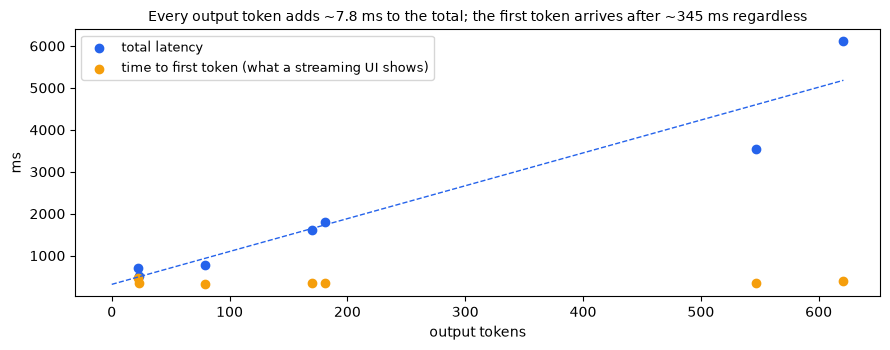

In [21]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter(out_tok, total_ms, color="#2563eb", label="total latency")
ax.scatter(out_tok, ttft_ms, color="#f59e0b", label="time to first token (what a streaming UI shows)")
xs = np.linspace(0, out_tok.max(), 50); ax.plot(xs, intercept + slope * xs, color="#2563eb", lw=1, ls="--")
ax.set_xlabel("output tokens"); ax.set_ylabel("ms"); ax.legend(fontsize=9)
ax.set_title(f"Every output token adds ~{slope:.1f} ms to the total; "
             f"the first token arrives after ~{np.median(ttft_ms):.0f} ms regardless", fontsize=10)
plt.tight_layout(); plt.show()

### Service tiers: price and latency per request
`serviceTier` is a request parameter (slide 10): **priority** for the customer-facing chat under load, **standard**
(`default` in the API), **flex** (about half price) for work that can wait. Not every model has tiers — the request
then fails with a `ValidationException`, so a client that sets tiers needs a fallback. First the probe:

In [22]:
def converse_tiered(model_id: str, prompt: str, tier: str) -> tuple[dict, str]:
    """Ask for a tier; if the model has no tiers, fall back to the default tier instead of failing the request."""
    try:
        return converse_measured(model_id, prompt, tier=tier, max_tokens=100, client=bare), tier
    except ClientError as e:
        if m.error_code(e) == "ValidationException" and "service tier is not supported" in str(e):
            return converse_measured(model_id, prompt, max_tokens=100), "default (fallback)"
        raise

PROBE = []
for model_id in (m.NOVA_MICRO, m.NOVA_LITE, m.NOVA2_LITE, m.NOVA_PRO, m.GPT_OSS_120B):
    r, used = converse_tiered(model_id, QUESTIONS[1] + SHORT, "flex")
    PROBE.append({"model": m.model_name(model_id), "asked": "flex", "used": used, "response says": r["tier"] or "–"})
m.table(PROBE)

model,asked,used,response says
Nova Micro,flex,default (fallback),–
Nova Lite,flex,default (fallback),–
Nova 2 Lite,flex,flex,flex
Nova Pro,flex,flex,flex
gpt-oss-120b,flex,flex,flex


In [23]:
TIERS = ("priority", "default", "flex")
TIER_RUNS = [{"tier": t, **converse_measured(m.NOVA2_LITE, q + SHORT, tier=t, max_tokens=150)}
             for q in QUESTIONS[:6] for t in TIERS]                  # interleaved: same questions, same minutes
rows = []
for t in TIERS:
    rs = [r for r in TIER_RUNS if r["tier"] == t]
    rows.append({"tier": t, "served as": ", ".join(sorted({str(r["tier"]) for r in rs})),
                 "TTFT p50 ms": statistics.median(r["ttft_ms"] for r in rs),
                 "total p50 ms": statistics.median(r["latency_ms"] for r in rs),
                 "$ / 1k requests": 1000 * mean([r["usd"] for r in billed(rs)])})
m.table(rows, fmt={"TTFT p50 ms": "{:.0f}", "total p50 ms": "{:.0f}", "$ / 1k requests": "${:.3f}"})
ratio = rows[2]["$ / 1k requests"] / rows[1]["$ / 1k requests"]
print(f"✓ flex costs {ratio:.0%} of default for the same requests" if ratio < 0.6 else f"✗ flex/default = {ratio:.0%}")

tier,served as,TTFT p50 ms,total p50 ms,$ / 1k requests
priority,priority,499,814,$0.313
default,default,566,871,$0.179
flex,flex,484,814,$0.088


✓ flex costs 49% of default for the same requests


> **Think about it:** Compare the priority and default latencies. What does priority buy you, and when would the
> table show it?

<details><summary>More questions</summary>

- Which of AnyCompany's workloads go to flex: nightly claim summaries, the chat, the fraud pre-check?
- Your router (slide 17) sets model *and* tier per request. What should it do when the monthly budget hits 90 %?
</details>

## 5 · Number of requests: a semantic cache
A call you never make costs nothing. A semantic cache embeds the question (Titan Text Embeddings V2)
and serves a stored answer when a new question means **nearly the same**. The threshold is a correctness
decision, so measure it like a classifier. 54 questions in 12 answer groups: each group has a question and two
paraphrases (same answer); plus 12 look-alikes with a *different* answer and 6 unrelated questions.

In [24]:
CACHE_SET = [  # (cached question, [two paraphrases], look-alike with a different answer)
    ("What is the deductible if my window breaks?",
     ["How much is the excess when a window gets smashed?", "If a window is broken, what do I pay myself?"],
     "What is the deductible if my roof breaks in a storm?"),
    ("How long do I have to report a claim?",
     ["What's the time limit for reporting a claim?", "By when must I tell you about a claim?"],
     "How long does it take to pay a claim?"),
    ("A pipe burst in the kitchen. What do I do first?",
     ["My kitchen pipe has burst - what should I do right now?", "Water pipe exploded in my kitchen, first steps?"],
     "A pipe burst in the kitchen. Is the new pipe covered?"),
    ("Is flood from the river covered?",
     ["Does the policy cover river flooding?", "The river overflowed into my house, am I insured?"],
     "Is water from a burst pipe covered?"),
    ("Is my stolen bike covered?",
     ["Do you pay if my bicycle is stolen?", "Someone stole my bike, will insurance cover it?"],
     "Is my stolen car covered?"),
    ("How do I cancel my policy?",
     ["I want to end my insurance policy, how?", "What are the steps to cancel my policy?"],
     "How do I cancel my claim?"),
    ("Do you pay for a hotel if we can't stay in the house?",
     ["Is temporary accommodation covered if my home is unlivable?", "Will you cover a hotel while the house is repaired?"],
     "Do you pay for a hotel when I travel on holiday?"),
    ("How do I upload photos of the damage?",
     ["Where can I send pictures of the damage?", "How do I submit damage photos?"],
     "How do I upload my driving licence?"),
    ("When will the adjuster call me?",
     ["How soon does the adjuster contact me?", "When can I expect a call from the loss adjuster?"],
     "When will the plumber call me?"),
    ("How long until I get paid after the claim is settled?",
     ["After settlement, when does the money arrive?", "How many days until the payout reaches my bank once settled?"],
     "How long until my premium refund arrives after I cancel?"),
    ("Can I throw away the wet carpet?",
     ["Am I allowed to dispose of the soaked carpet?", "Can I get rid of the water-damaged carpet now?"],
     "Can I replace the wet carpet with a more expensive one?"),
    ("What does my policy cover for storm damage?",
     ["Which storm damage is insured under my policy?", "Am I covered if a storm damages my house?"],
     "What does my policy cover for earthquake damage?")]

In [25]:
UNRELATED = ["Do you offer pet insurance?", "How do I change my email address?", "Is there a discount for an alarm system?",
             "Can I pay my premium monthly?", "Which languages does your support speak?", "What's your office address?"]
# (question, group it should hit; None = should miss)
PROBES = ([(p, g) for g, (_, paras, _) in enumerate(CACHE_SET) for p in paras] +
          [(look, None) for _, _, look in CACHE_SET] + [(u, None) for u in UNRELATED])

def embed_one(text: str) -> np.ndarray:
    body = json.dumps({"inputText": text, "dimensions": 1024, "normalize": True})   # normalized → dot product = cosine
    return np.array(json.loads(bedrock.invoke_model(modelId=m.TITAN_EMBED_V2, body=body)["body"].read())["embedding"])

with ThreadPoolExecutor(4) as pool:
    BASE_VEC = np.array(list(pool.map(embed_one, [c[0] for c in CACHE_SET])))
    PROBE_VEC = np.array(list(pool.map(embed_one, [p for p, _ in PROBES])))
print(f"{len(BASE_VEC)} cached + {len(PROBE_VEC)} probe embeddings, {BASE_VEC.shape[1]} dimensions")

12 cached + 42 probe embeddings, 1024 dimensions


**Scoped keys** (slide 37): a hit must also match the entities in the question — tenant, document version, and the
perils, insured objects and actions of the product catalogue (the policy wording's own terms: *escape of water*,
*flood*, *glass*…). Here a small vocabulary maps words to those entities; in production they come from your NER or
slot filler.

In [26]:
ENTITIES = {"glass": r"window|glass|pane", "roof": r"roof", "pipe": r"pipe", "flood": r"flood|river",
            "escape_of_water": r"water|wet|soak", "bicycle": r"bike|bicycle", "car": r"\bcar\b|vehicle",
            "cancel": r"cancel|end my", "hotel": r"hotel|accommodation", "travel": r"travel|holiday",
            "photos": r"photo|picture", "licence": r"licen[cs]e", "adjuster": r"adjuster", "plumber": r"plumber",
            "payout": r"paid|payout|money arrive|settle", "refund": r"refund|premium", "carpet": r"carpet",
            "replace": r"replace|more expensive", "storm": r"storm", "earthquake": r"earthquake",
            "report": r"report|tell you",
            "claim": r"\bclaim\b", "policy": r"\bpolicy\b"}

def scope(question: str, tenant: str = "anycompany", doc_version: str = "HP-2026") -> tuple:
    found = frozenset(e for e, rx in ENTITIES.items() if re.search(rx, question, re.I)) - {"claim", "policy"}
    return (tenant, doc_version, found)          # generic words don't scope; the insured object / action does

In [27]:
# Any answered question becomes a cache key - so evaluate PAIRS of questions, not just probes against a seed set.
ALL_Q = [c[0] for c in CACHE_SET] + [p for p, _ in PROBES]
GROUP = list(range(len(CACHE_SET))) + [g if g is not None else f"other-{i}" for i, (_, g) in enumerate(PROBES)]
VECS = np.vstack([BASE_VEC, PROBE_VEC])
iu = np.triu_indices(len(ALL_Q), 1)                       # every unordered pair once
pair_sim = (VECS @ VECS.T)[iu]
same_answer = np.array([GROUP[i] == GROUP[j] for i, j in zip(*iu)])
same_scope = np.array([scope(ALL_Q[i]) == scope(ALL_Q[j]) for i, j in zip(*iu)])
print(f"{len(pair_sim):,} pairs, {same_answer.sum()} of them share an answer")
pairs = sorted(zip(pair_sim, same_answer, *iu), key=lambda p: -p[0])
close_wrong = [p for p in pairs if not p[1]][:3]                   # look-alikes: close, but a different answer
far_right = [p for p in pairs if p[1]][-3:]                        # paraphrases: same answer, far apart
m.table([{"pair": f"{ALL_Q[i]}  |  {ALL_Q[j]}", "cosine": float(sim), "same answer?": "yes" if same else "NO"}
         for sim, same, i, j in close_wrong + far_right], fmt={"cosine": "{:.2f}"})

1,431 pairs, 36 of them share an answer


pair,cosine,same answer?
A pipe burst in the kitchen. Is the new pipe covered? | Is water from a burst pipe covered?,0.70,NO
How long until I get paid after the claim is settled? | How long does it take to pay a claim?,0.67,NO
Is my stolen bike covered? | Is my stolen car covered?,0.67,NO
Is temporary accommodation covered if my home is unlivable? | Will you cover a hotel while the house is repaired?,0.46,yes
How long until I get paid after the claim is settled? | How many days until the payout reaches my bank once settled?,0.46,yes
Do you pay for a hotel if we can't stay in the house? | Is temporary accommodation covered if my home is unlivable?,0.36,yes


In [28]:

SWEEP = []
for keys, allowed in (("vector only", np.ones_like(same_scope)), ("scoped", same_scope)):
    for t in np.round(np.arange(0.50, 0.96, 0.05), 2):
        hit = (pair_sim >= t) & allowed
        right = int((hit & same_answer).sum())
        SWEEP.append({"keys": keys, "threshold": t, "pairs that hit": int(hit.sum()), "right": right,
                      "wrong answers served": int(hit.sum()) - right,
                      "precision": right / hit.sum() if hit.sum() else 1.0, "recall": right / same_answer.sum()})
m.table([s for s in SWEEP if s["threshold"] in (0.5, 0.6, 0.7, 0.8, 0.9)],
        fmt={"precision": "{:.0%}", "recall": "{:.0%}", "threshold": "{:.2f}"})

keys,threshold,pairs that hit,right,wrong answers served,precision,recall
vector only,0.50,49,31,18,63%,86%
vector only,0.60,32,24,8,75%,67%
vector only,0.70,15,14,1,93%,39%
vector only,0.80,8,8,0,100%,22%
vector only,0.90,2,2,0,100%,6%
scoped,0.50,32,29,3,91%,81%
scoped,0.60,24,22,2,92%,61%
scoped,0.70,12,12,0,100%,33%
scoped,0.80,7,7,0,100%,19%
scoped,0.90,2,2,0,100%,6%


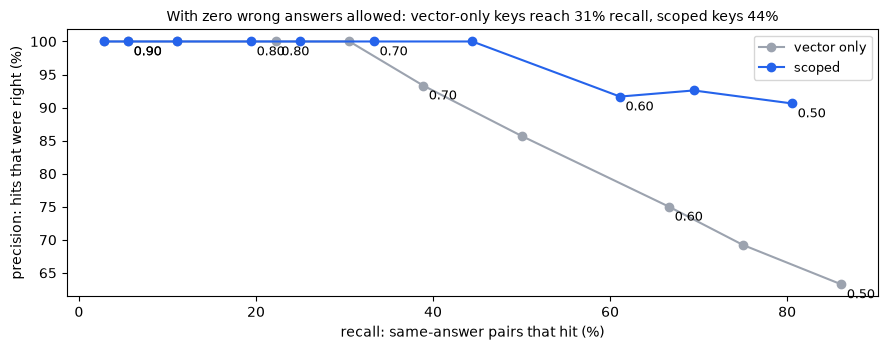

vector only: threshold 0.75 → recall 31%   scoped: threshold 0.65 → recall 44%


In [29]:
def best_threshold(keys: str, min_precision: float = 1.0):
    """The lowest threshold that never served a wrong answer on this set = most hits at zero wrong answers."""
    ok = [s for s in SWEEP if s["keys"] == keys and s["precision"] >= min_precision]
    return min(ok, key=lambda s: s["threshold"]) if ok else None

fig, ax = plt.subplots(figsize=(9, 3.6))
for keys, color in (("vector only", "#9ca3af"), ("scoped", "#2563eb")):
    pts = [s for s in SWEEP if s["keys"] == keys]
    ax.plot([s["recall"] * 100 for s in pts], [s["precision"] * 100 for s in pts], marker="o", color=color, label=keys)
    for s in pts[::2]:
        ax.annotate(f"{s['threshold']:.2f}", (s["recall"] * 100, s["precision"] * 100), xytext=(4, -10),
                    textcoords="offset points", fontsize=9)
V, S = best_threshold("vector only"), best_threshold("scoped")
ax.set_xlabel("recall: same-answer pairs that hit (%)"); ax.set_ylabel("precision: hits that were right (%)")
ax.legend(fontsize=9)
ax.set_title(f"With zero wrong answers allowed: vector-only keys reach {V['recall']:.0%} recall, "
             f"scoped keys {S['recall']:.0%}", fontsize=10)
plt.tight_layout(); plt.show()
print(f"vector only: threshold {V['threshold']:.2f} → recall {V['recall']:.0%}   "
      f"scoped: threshold {S['threshold']:.2f} → recall {S['recall']:.0%}")

### Replay: real traffic through the cache
The cache starts empty. The 54 questions arrive in random order; a miss calls Nova Lite (with the cached prompt prefix
from §1) and stores the answer; a hit serves the stored answer, with the scoped keys and the threshold chosen above.
The threshold was tuned on these same questions, so the replay shows hit rate, latency and cost — not how the
threshold generalizes (that needs a held-out set from real traffic).

In [30]:
class SemanticCache:
    """In memory for the demo. In production: ElastiCache for Valkey vector search (FT.SEARCH KNN with tag filters
    for the scope), shared by all app instances, with a TTL per entry."""
    def __init__(self, threshold: float):
        self.threshold, self.vecs, self.entries = threshold, np.zeros((0, 1024)), []
    def get(self, vec, key):
        if not self.entries:
            return None, 0.0
        sims = np.where([e["key"] == key for e in self.entries], self.vecs @ vec, -1.0)
        i = int(np.argmax(sims))
        return (self.entries[i] if sims[i] >= self.threshold else None), float(sims[i])
    def put(self, vec, key, question, answer, group):
        self.vecs = np.vstack([self.vecs, vec])
        self.entries.append({"key": key, "q": question, "a": answer, "group": group})

In [31]:
TRAFFIC = [(c[0], g) for g, c in enumerate(CACHE_SET)] + [(p, g) for p, g in PROBES]
TRAFFIC = [(q, g if g is not None else f"other-{i}") for i, (q, g) in enumerate(TRAFFIC)]
random.Random(7).shuffle(TRAFFIC)
VEC = dict(zip([c[0] for c in CACHE_SET], BASE_VEC)) | dict(zip([p for p, _ in PROBES], PROBE_VEC))

sc, REPLAY = SemanticCache(S["threshold"]), []
for q, group in TRAFFIC:
    t0 = time.perf_counter()
    vec = embed_one(q)                                   # re-embedded: the replay pays the real embedding latency
    entry, sim = sc.get(vec, scope(q))
    if entry:
        REPLAY.append({"q": q, "hit": True, "right": entry["group"] == group, "ms": (time.perf_counter() - t0) * 1000})
        continue
    r = converse_measured(LITE_REGIONAL, q + SHORT, system=CACHED, max_tokens=150)
    sc.put(vec, scope(q), q, r["text"], group)
    REPLAY.append({"q": q, "hit": False, "right": True, "ms": (time.perf_counter() - t0) * 1000,
                   "model_usd": r["usd"] if r["usage_ok"] else None})

In [32]:

hits = [r for r in REPLAY if r["hit"]]; misses = [r for r in REPLAY if not r["hit"]]
HIT_RATE = len(hits) / len(REPLAY)
model_usd = mean([r["model_usd"] for r in misses if r["model_usd"] is not None])   # one call (complete usage only)
embed_usd = mean([len(q.split()) * 1.3 for q, _ in TRAFFIC]) * m.PRICES[m.TITAN_EMBED_V2]["in"] / 1000
print(f"{len(REPLAY)} requests: {len(hits)} hits ({HIT_RATE:.0%}), {len(misses)} model calls, "
      f"wrong answers served: {sum(not r['right'] for r in hits)}")
print(f"latency p50: hit {statistics.median(r['ms'] for r in hits):.0f} ms "
      f"vs miss {statistics.median(r['ms'] for r in misses):.0f} ms")
print(f"$ per 1k requests: {1000 * ((1 - HIT_RATE) * model_usd + embed_usd):.4f} with the cache "
      f"vs {1000 * model_usd:.4f} without")
print("✓ no wrong answer served" if all(r["right"] for r in hits) else "✗ the cache served a wrong answer: " +
      "; ".join(r["q"] for r in hits if not r["right"]))

54 requests: 12 hits (22%), 42 model calls, wrong answers served: 0
latency p50: hit 155 ms vs miss 829 ms
$ per 1k requests: 0.0690 with the cache vs 0.0884 without
✓ no wrong answer served


> **Think about it:** The threshold was tuned on 54 questions. What happens on the first day a customer asks about
> something the vocabulary doesn't know — and what would you monitor to catch it?

<details><summary>More questions</summary>

- Which answers must never be cached at all (slide 40)?
- The policy wording changes on 1 January. How does the scope key make invalidation one line of code?
</details>

## 6 · The bill, the quota and the dashboard
A monthly waterfall for the support assistant from the numbers measured above (per-request dollars from §1, hit rate
from §5). Assumption: `MONTHLY_REQUESTS` requests a month.

step,$ / month,vs baseline
baseline: Nova Pro,"$4,290",100.0%
right-size: Nova Lite,$324,7.6%
+ prompt cache (in-Region),$89,2.1%
+ semantic cache (22% hits),$70,1.6%


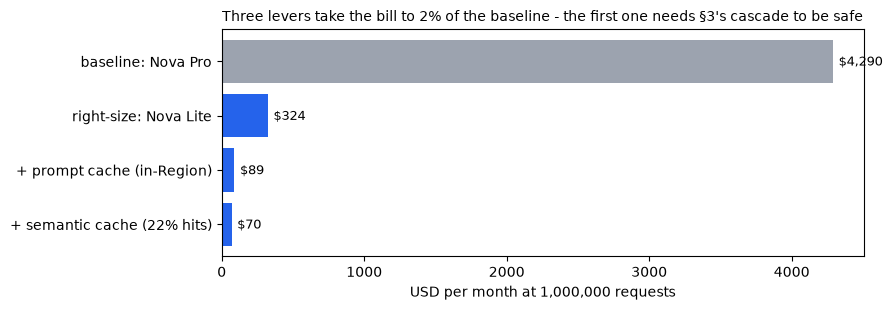

In [33]:
per_req = {r["arm"]: r["$ / 1k requests"] / 1000 for r in CACHE_TABLE}
STEPS = [("baseline: Nova Pro", per_req["Nova Pro, no cache"]),
         ("right-size: Nova Lite", per_req["Nova Lite, no cache"]),
         ("+ prompt cache (in-Region)", per_req["Nova Lite, cachePoint, in-Region"]),
         (f"+ semantic cache ({HIT_RATE:.0%} hits)",
          per_req["Nova Lite, cachePoint, in-Region"] * (1 - HIT_RATE) + embed_usd)]
WATERFALL = [{"step": s, "$ / month": MONTHLY_REQUESTS * usd, "vs baseline": usd / STEPS[0][1]} for s, usd in STEPS]
m.table(WATERFALL, fmt={"$ / month": "${:,.0f}", "vs baseline": "{:.1%}"})
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh([w["step"] for w in WATERFALL][::-1], [w["$ / month"] for w in WATERFALL][::-1],
        color=["#2563eb"] * 3 + ["#9ca3af"])
for i, w in enumerate(WATERFALL[::-1]):
    ax.annotate(f"${w['$ / month']:,.0f}", (w["$ / month"], i), xytext=(4, -3), textcoords="offset points", fontsize=9)
ax.set_xlabel(f"USD per month at {MONTHLY_REQUESTS:,} requests")
ax.set_title(f"Three levers take the bill to {WATERFALL[-1]['vs baseline']:.0%} of the baseline - "
             "the first one needs §3's cascade to be safe", fontsize=10)
plt.tight_layout(); plt.show()

**Will it fit?** Throughput is capped by per-model quotas in requests *and* tokens per minute (slide 28). Read the
account's applied values from **Service Quotas** (the AWS default where nothing is applied) and check the peak.

In [34]:
def find_quotas(words: list[str]) -> dict:
    """Quota codes by name, paginated (NextToken), then the value applied to THIS account."""
    found, kw = {}, {"ServiceCode": "bedrock", "MaxResults": 100}
    while True:
        page = quotas.list_aws_default_service_quotas(**kw)
        for q in page["Quotas"]:
            if q["QuotaName"] in words:
                found[q["QuotaName"]] = {"code": q["QuotaCode"], "default": q["Value"]}
        if not page.get("NextToken"):
            break
        kw["NextToken"] = page["NextToken"]
    for name, q in found.items():
        try:
            q["applied"] = quotas.get_service_quota(ServiceCode="bedrock", QuotaCode=q["code"])["Quota"]["Value"]
        except ClientError:
            q["applied"] = q["default"]
    return found

In [35]:
Q = find_quotas(["On-demand model inference requests per minute for Amazon Nova Lite",
                 "On-demand model inference tokens per minute for Amazon Nova Lite",
                 "Cross-region model inference requests per minute for Amazon Nova Lite"])
PEAK_FACTOR = 10                         # peak minute = 10 × the average minute (support desks are spiky)
peak_rpm = MONTHLY_REQUESTS * (1 - HIT_RATE) / (30 * 24 * 60) * PEAK_FACTOR
tokens_per_req = mean([r["usage"]["inputTokens"] + r["usage"].get("cacheReadInputTokens", 0) + r["usage"]["outputTokens"]
                       for r in billed(CACHE_RUNS) if r["arm"] == "Nova Lite, cachePoint, in-Region"])
need = {"requests per minute": peak_rpm, "tokens per minute": peak_rpm * tokens_per_req}
m.table([{"quota": n, "AWS default": q["default"], "this account": q["applied"],
          "peak need": need["tokens per minute" if "tokens" in n else "requests per minute"]} for n, q in Q.items()],
        fmt={"AWS default": "{:,.0f}", "this account": "{:,.0f}", "peak need": "{:,.0f}"})
rpm_q = Q["On-demand model inference requests per minute for Amazon Nova Lite"]["applied"]
breaks_at = rpm_q / PEAK_FACTOR * (30 * 24 * 60) / (1 - HIT_RATE)
xr_rpm = Q["Cross-region model inference requests per minute for Amazon Nova Lite"]["applied"]
print(f"peak uses {peak_rpm / rpm_q:.0%} of this account's on-demand RPM quota; the quota is hit at about "
      f"{breaks_at:,.0f} requests/month → beyond that: a quota increase, the us. profile ({xr_rpm:,.0f} RPM) "
      "or a queue (Module 10)")

quota,AWS default,this account,peak need
Cross-region model inference requests per minute for Amazon Nova Lite,"4,000",400,180
On-demand model inference tokens per minute for Amazon Nova Lite,"4,000,000","4,000,000","953,238"
On-demand model inference requests per minute for Amazon Nova Lite,"2,000",200,180


peak uses 90% of this account's on-demand RPM quota; the quota is hit at about 1,110,857 requests/month → beyond that: a quota increase, the us. profile (400 RPM) or a queue (Module 10)


**Watch it in production.** Bedrock publishes per-model metrics to CloudWatch, including `TimeToFirstToken`,
`CacheReadInputTokenCount` and the per-tier dimensions. A dashboard for the models this notebook used — the console
part opens it. (The account is shared: other traffic shows up too.)

In [36]:
def metric(name, model_id, stat="Sum", **dims):
    return ["AWS/Bedrock", name, "ModelId", model_id, *[x for kv in dims.items() for x in kv], {"stat": stat}]

def widget(title, metrics, x, y, stat_note=""):
    return {"type": "metric", "x": x, "y": y, "width": 12, "height": 6, "properties": {
        "title": title + stat_note, "region": m.REGION, "period": 60, "view": "timeSeries", "stacked": False,
        "metrics": metrics}}

USED = [LITE_REGIONAL, PRO_REGIONAL, m.NOVA_LITE, m.NOVA_MICRO, m.NOVA2_LITE, m.GPT_OSS_120B]
BODY = {"widgets": [
    widget("Invocations and throttles",
           [metric("Invocations", x) for x in USED] + [metric("InvocationThrottles", x) for x in USED[:3]], 0, 0),
    widget("Input vs cache-read tokens (Nova Lite in-Region)",
           [metric(name, LITE_REGIONAL) for name in ("InputTokenCount", "CacheReadInputTokenCount", "OutputTokenCount")],
           12, 0),
    widget("Time to first token p50", [metric("TimeToFirstToken", x, "p50") for x in USED], 0, 6),
    widget("Nova 2 Lite latency by service tier p50",
           [metric("InvocationLatency", m.NOVA2_LITE, "p50", ServiceTier=t, ResolvedServiceTier=t) for t in TIERS], 12, 6)]}
cloudwatch.put_dashboard(DashboardName=DASHBOARD, DashboardBody=json.dumps(BODY))
print(json.dumps(BODY["widgets"][3]["properties"]["metrics"][0]))
now = time.time()
data = cloudwatch.get_metric_data(StartTime=now - 1800, EndTime=now, MetricDataQueries=[{"Id": "ttft", "MetricStat": {
    "Metric": {"Namespace": "AWS/Bedrock", "MetricName": "Invocations",
               "Dimensions": [{"Name": "ModelId", "Value": LITE_REGIONAL}]},
    "Period": 60, "Stat": "Sum"}}])["MetricDataResults"][0]
print(f"dashboard {DASHBOARD}: ✓ created · Nova Lite in-Region invocations in the last 30 min: {sum(data['Values']):.0f}"
      + ("" if data["Values"] else " (metrics arrive 1-3 min after the calls - open the dashboard in a minute)"))

["AWS/Bedrock", "InvocationLatency", "ModelId", "us.amazon.nova-2-lite-v1:0", "ServiceTier", "priority", "ResolvedServiceTier", "priority", {"stat": "p50"}]
dashboard mlaidp2-m07-cost-latency: ✓ created · Nova Lite in-Region invocations in the last 30 min: 44


> **Think about it:** Which one CloudWatch metric would you alarm on for this assistant — and on which statistic?

## Cleanup — don't skip this
Deletes the CloudWatch dashboard. Run it **after Part 2** (console) if you show the dashboard there. Nothing else
was created: every other step only called models.

In [37]:
try:
    cloudwatch.delete_dashboards(DashboardNames=[DASHBOARD])
except ClientError as e:
    if m.error_code(e) not in ("ResourceNotFound", "DashboardNotFoundError"):
        raise
left = [d["DashboardName"] for d in cloudwatch.list_dashboards(DashboardNamePrefix="mlaidp2-m07")["DashboardEntries"]]
print("✓ nothing left" if not left else f"✗ still there: {left}")

✓ nothing left
